# ขั้นที่ 1: Feature ภูมิศาสตร์โบราณ (ทวีปพันเจีย)

ย้อนตำแหน่งของแต่ละจุดในไทยกลับไปในอดีต แล้วสร้าง feature ที่บอก "สภาพแวดล้อมในอดีต" ของจุดนั้น
ซึ่งเกี่ยวกับชนิดซากโดยตรง: จุดที่เคยเป็นทะเลตื้นเขตร้อนมักพบแบรคิโอพอด/ปะการัง ส่วนจุดที่เป็นแผ่นดินในครีเทเชียสมักพบไดโนเสาร์

| แหล่งข้อมูล (EarthByte) | ใช้ทำอะไร |
|---|---|
| **Scotese & Wright 2018** (PALEOMAP plate model) | ย้อนตำแหน่ง + ระบุแผ่นเปลือกโลก (คู่กับ PaleoDEM) |
| **Merdith et al. 2021** (1 Ga plate model) | ย้อนตำแหน่ง + ระบุแผ่นเปลือกโลก (แบ่ง terrane ละเอียดกว่า, ย้อนได้ถึง 410 ล้านปีสำหรับไทย) |
| **PaleoDEM, Scotese & Wright 2018** (0.2°, ทุก 5 ล้านปี) | ความสูง/ความลึกโบราณ ณ ตำแหน่งที่ย้อนแล้ว → ทะเลหรือแผ่นดิน |

**ช่วงเวลา** (ใช้ช่วงคงที่ เพราะตอนทำนายยังไม่รู้ยุคของซาก): 480, 400, 300, 280, 270, 260, 250 (พันเจีย), 240, 230, 200, 150, 120, 66, 0 ล้านปี
(ช่วง 280–230 เพิ่มให้ละเอียดในเพอร์เมียน–ไทรแอสซิก ซึ่งเป็นยุคที่พบซากทะเลไทยมากที่สุด)

**จุดที่คำนวณ feature** (ใช้ซ้ำในขั้นต่อ ๆ ไป)
| ชุด | จำนวน | ใช้ทำอะไร |
|---|---|---|
| `dmr_site` | 518 | แหล่งของ ทธ. (presence + label ของงานที่ 1, 2) |
| `pbdb` | 290 | collection ของ PBDB ในไทย หลังตัดพิกัดหยาบและพิกัดซ้ำ (presence อิสระ สำหรับตรวจโมเดลโอกาสพบซาก) |
| `bg_uniform` | 5,000 | จุดสุ่มสม่ำเสมอทั่วไทย (background แบบ Block et al. 2016) |
| `bg_bias` | 5,000 | จุดสุ่มถ่วงตามความหนาแน่นของแหล่ง (ปรับความลำเอียงของการสำรวจ) |

**การรันต่อเมื่อหยุดกลางทาง**: ทุกขั้นที่ใช้เวลาจะบันทึกผลเป็นไฟล์ cache (`data/features/pangea_cache/`) และข้ามส่วนที่ทำเสร็จแล้ว
ลบไฟล์ใน cache ถ้าต้องการคำนวณใหม่

In [1]:
import glob
import json
import logging
import re
import warnings
from pathlib import Path

logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pygplates
import xarray as xr
from matplotlib.colors import TwoSlopeNorm
from matplotlib import font_manager
from plate_model_manager import PlateModelManager
from shapely import contains_xy
from sklearn.neighbors import BallTree
from tqdm.auto import tqdm

DATA = Path("../data")
FEAT = DATA / "features"
CACHE = FEAT / "pangea_cache"
CACHE.mkdir(parents=True, exist_ok=True)
SEED = 42

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 60, "display.width", 180)
INK, MUTED = "#52514e", "#8a8984"
SOURCE_COLOR = {"dmr_site": "#2a78d6", "pbdb": "#eb6834", "bg_uniform": "#bdbcb6", "bg_bias": "#1baf7a"}

TIMES = [480, 400, 300, 280, 270, 260, 250, 240, 230, 200, 150, 120, 66, 0]
MODELS = {"sw18": "scotese_and_wright2018", "me21": "merdith2021"}

## 1. ชุดจุด

- **แหล่ง ทธ.** จาก `sites_period_final` (notebook 05)
- **PBDB**: ตัด collection ที่พิกัดหยาบหรืออยู่นอกไทยออกแบบเดียวกับ notebook 03
- **background**: สุ่มบนแผ่นดินไทย (ภายในขอบเขตจังหวัดของ ทธ.) และอยู่ห่างแหล่งที่รู้จัก (ทธ. + PBDB) อย่างน้อย 2 กม.
  - `bg_uniform`: สุ่มสม่ำเสมอ
  - `bg_bias`: สุ่มจากจุดเดียวกัน แต่ถ่วงน้ำหนักด้วยความหนาแน่นของแหล่ง ทธ. (Gaussian kernel σ = 25 กม.)
    ทำให้ background อยู่ในพื้นที่ที่ "มีคนไปสำรวจ" เหมือนแหล่ง โมเดลจึงต้องเรียนความต่างของสภาพพื้นที่ ไม่ใช่แค่เรียนว่าคนไปสำรวจที่ไหน
- ใช้ `SEED = 42` และบันทึกไว้ที่ `data/features/points.parquet` รันซ้ำจะได้ชุดเดิม

In [2]:
POINTS_FILE = FEAT / "points.parquet"
N_BG = 5000
MIN_DIST_KM = 2.0
KDE_SIGMA_KM = 25.0

if POINTS_FILE.exists():
    points = pd.read_parquet(POINTS_FILE)
    print("โหลดชุดจุดจาก cache:", POINTS_FILE)
else:
    sites = pd.read_csv(DATA / "processed" / "sites_period_final.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
    dmr = pd.DataFrame({"point_id": "dmr_" + sites.OBJECTID.astype(str), "source": "dmr_site",
                        "lon": sites.longitude, "lat": sites.latitude, "ref_id": sites.OBJECTID.astype(str)})

    prov = gpd.read_file(DATA / "dmr_admin" / "provinces.geojson")
    thai = prov.union_all()

    colls = pd.read_csv(DATA / "pbdb_thailand" / "collections.csv", low_memory=False)
    coarse = (colls.latlng_basis.eq("based on political unit") | colls.latlng_precision.astype(str).isin(["0", "1"])
              | colls.geogscale.eq("basin"))
    ok = ~coarse & contains_xy(thai, colls.lng.values, colls.lat.values)
    pbdb = pd.DataFrame({"point_id": "pbdb_" + colls.loc[ok, "collection_no"].astype(str), "source": "pbdb",
                         "lon": colls.loc[ok, "lng"], "lat": colls.loc[ok, "lat"], "ref_id": colls.loc[ok, "collection_no"].astype(str)})
    pbdb = pbdb.drop_duplicates(["lon", "lat"])

    # กลุ่มจุดผู้สมัครทั่วไทย -> คัดที่อยู่บนแผ่นดินและห่างแหล่งที่รู้จัก
    rng = np.random.default_rng(SEED)
    minx, miny, maxx, maxy = thai.bounds
    cand = []
    with tqdm(total=200_000, desc="สุ่มจุดบนแผ่นดินไทย") as bar:
        while sum(len(c) for c in cand) < 200_000:
            x = rng.uniform(minx, maxx, 100_000)
            y = rng.uniform(miny, maxy, 100_000)
            keep = contains_xy(thai, x, y)
            cand.append(np.c_[x[keep], y[keep]])
            bar.update(int(keep.sum()))
    cand = np.vstack(cand)[:200_000]

    R = 6371.0
    known = np.radians(np.r_[dmr[["lat", "lon"]].values, pbdb[["lat", "lon"]].values])
    tree_known = BallTree(known, metric="haversine")
    d_known = tree_known.query(np.radians(cand[:, ::-1]), k=1)[0][:, 0] * R
    cand = cand[d_known >= MIN_DIST_KM]

    # ความหนาแน่นของแหล่ง ทธ. ที่แต่ละจุดผู้สมัคร (Gaussian kernel)
    tree_dmr = BallTree(np.radians(dmr[["lat", "lon"]].values), metric="haversine")
    ind, dist = tree_dmr.query_radius(np.radians(cand[:, ::-1]), r=4 * KDE_SIGMA_KM / R, return_distance=True)
    dens = np.array([np.exp(-0.5 * (d * R / KDE_SIGMA_KM) ** 2).sum() for d in tqdm(dist, desc="ความหนาแน่นของแหล่ง")])

    uni_idx = rng.choice(len(cand), N_BG, replace=False)
    w = dens / dens.sum()
    bias_idx = rng.choice(len(cand), N_BG, replace=False, p=w)
    bg_u = pd.DataFrame({"point_id": [f"bgu_{i}" for i in range(N_BG)], "source": "bg_uniform",
                         "lon": cand[uni_idx, 0], "lat": cand[uni_idx, 1], "ref_id": None})
    bg_b = pd.DataFrame({"point_id": [f"bgb_{i}" for i in range(N_BG)], "source": "bg_bias",
                         "lon": cand[bias_idx, 0], "lat": cand[bias_idx, 1], "ref_id": None})
    points = pd.concat([dmr, pbdb, bg_u, bg_b], ignore_index=True)
    points.to_parquet(POINTS_FILE, index=False)
    print("บันทึก", POINTS_FILE)

points.source.value_counts().to_frame("จุด").T

โหลดชุดจุดจาก cache: ../data/features/points.parquet


source,bg_uniform,bg_bias,dmr_site,pbdb
จุด,5000,5000,518,290


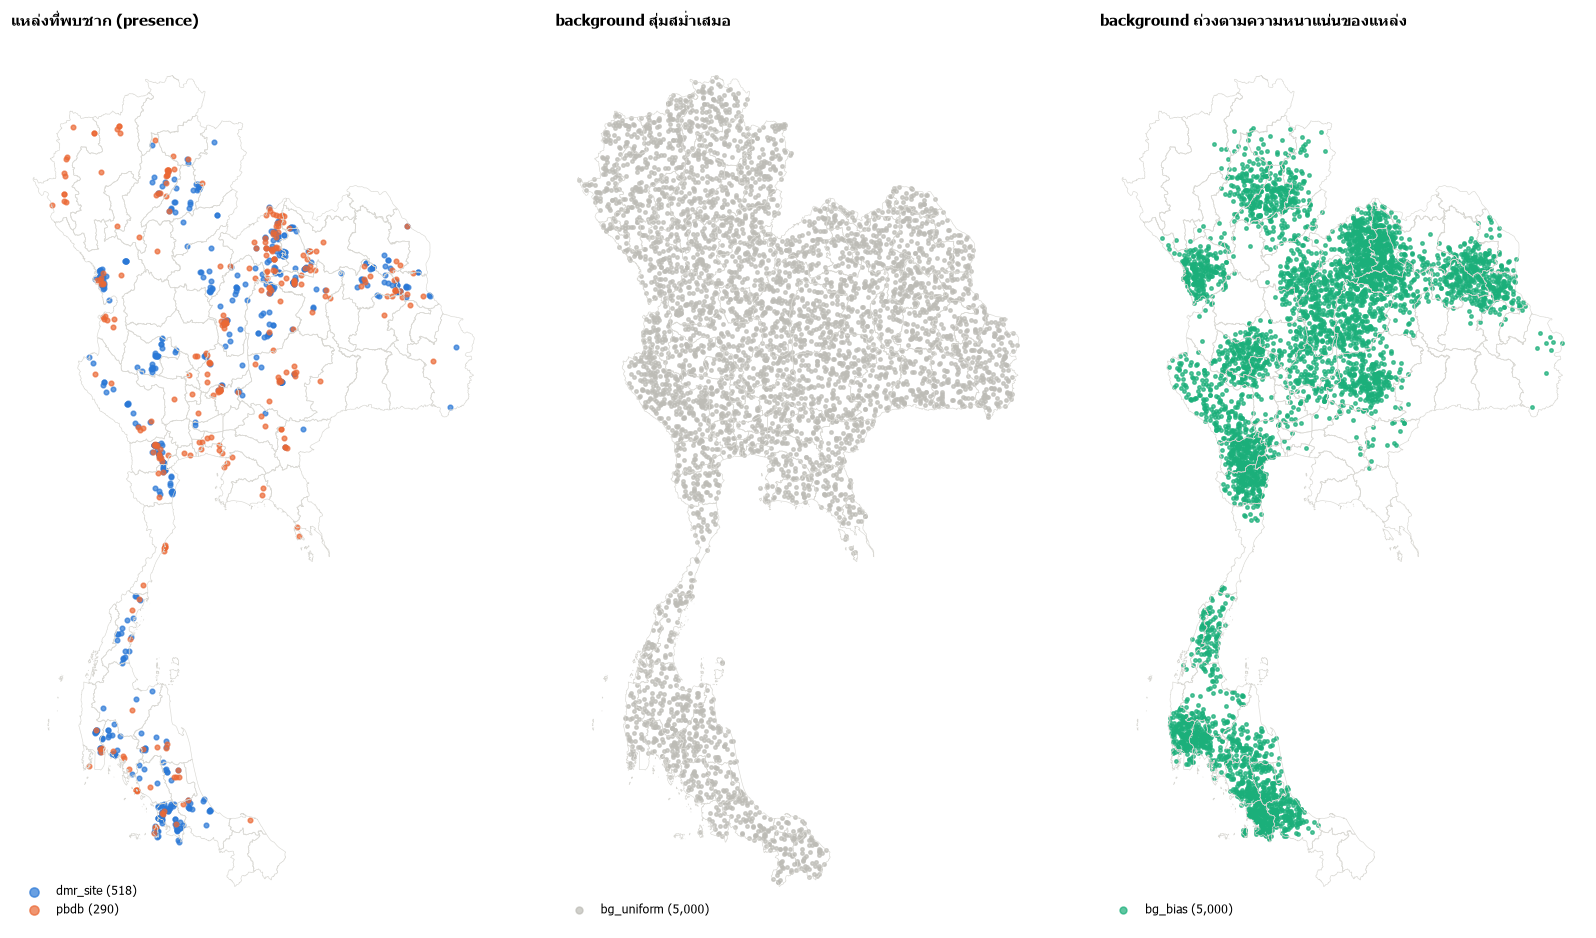

In [3]:
prov = gpd.read_file(DATA / "dmr_admin" / "provinces.geojson")
fig, axes = plt.subplots(1, 3, figsize=(15, 8.5))
for ax, srcs, title in [(axes[0], ["dmr_site", "pbdb"], "แหล่งที่พบซาก (presence)"),
                        (axes[1], ["bg_uniform"], "background สุ่มสม่ำเสมอ"),
                        (axes[2], ["bg_bias"], "background ถ่วงตามความหนาแน่นของแหล่ง")]:
    prov.boundary.plot(ax=ax, color="#d9d8d3", linewidth=0.4)
    for s in srcs:
        sub = points[points.source.eq(s)]
        ax.scatter(sub.lon, sub.lat, s=5 if s.startswith("bg") else 9, color=SOURCE_COLOR[s], alpha=0.7, label=f"{s} ({len(sub):,})")
    ax.set_axis_off()
    ax.legend(loc="lower left", frameon=False, fontsize=8, markerscale=2)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=10)
plt.tight_layout()

## 2. ระบุแผ่นเปลือกโลก (plate partition)

หาว่าแต่ละจุดอยู่บน static polygon ไหนของแต่ละโมเดล ได้ `plate_id`, ชื่อ polygon และช่วงเวลาที่ polygon นั้นมีอยู่
(ถ้าย้อนไปเก่ากว่าเวลาเริ่มต้นของ polygon จะย้อนไม่ได้ → ค่าว่าง)

In [4]:
pm = PlateModelManager()
MODEL = {}
for key, name in MODELS.items():
    m = pm.get_model(name, data_dir=str(DATA / "paleo"))
    static = pygplates.FeatureCollection()
    for f in m.get_layer("StaticPolygons"):
        static.add(pygplates.FeatureCollection(f))
    MODEL[key] = {"rot": pygplates.RotationModel(m.get_rotation_model()), "static": static}
    print(key, name, "| static polygons:", len(static))


def partition(points, key):
    cache = CACHE / f"partition_{key}.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    part = pygplates.PlatePartitioner(MODEL[key]["static"], MODEL[key]["rot"])
    rows = []
    for pid, lon, lat in tqdm(points[["point_id", "lon", "lat"]].itertuples(index=False), total=len(points), desc=f"partition {key}"):
        poly = part.partition_point(pygplates.PointOnSphere(lat, lon))
        if poly is None:
            rows.append((pid, np.nan, None, np.nan))
        else:
            f = poly.get_feature()
            rows.append((pid, f.get_reconstruction_plate_id(), f.get_name(), f.get_valid_time()[0]))
    df = pd.DataFrame(rows, columns=["point_id", f"pg_{key}_plate", f"pg_{key}_terrane", f"pg_{key}_begin_ma"])
    df.to_parquet(cache, index=False)
    return df


parts = {key: partition(points, key) for key in MODELS}
for key, df in parts.items():
    d = df.merge(points[["point_id", "source"]], on="point_id")
    print(f"\n{key}: ไม่อยู่บน polygon ใด {d[f'pg_{key}_plate'].isna().sum()} จุด")
    display(d[d.source.eq("dmr_site")].groupby([f"pg_{key}_plate", f"pg_{key}_terrane"], dropna=False).size()
            .rename("แหล่ง ทธ.").sort_values(ascending=False).head(8).to_frame())

sw18 scotese_and_wright2018 | static polygons: 240


me21 merdith2021 | static polygons: 2391

sw18: ไม่อยู่บน polygon ใด 0 จุด


,,แหล่ง ทธ.
pg_sw18_plate,pg_sw18_terrane,
616,,298
615,,220



me21: ไม่อยู่บน polygon ใด 0 จุด


แหล่ง ทธ.
pg_me21_plate pg_me21_terrane                
604           Indochina                   168
647           Malay Peninsula             116
603           Sino/Burma/Malaya            85
60302         Sino/Burma/Malaya            60
60401         Simao (Metcalfe)             52
60301         Sukhothai (Metcalfe)         34
60402         Malay Peninsula               2
              Indochina                     1

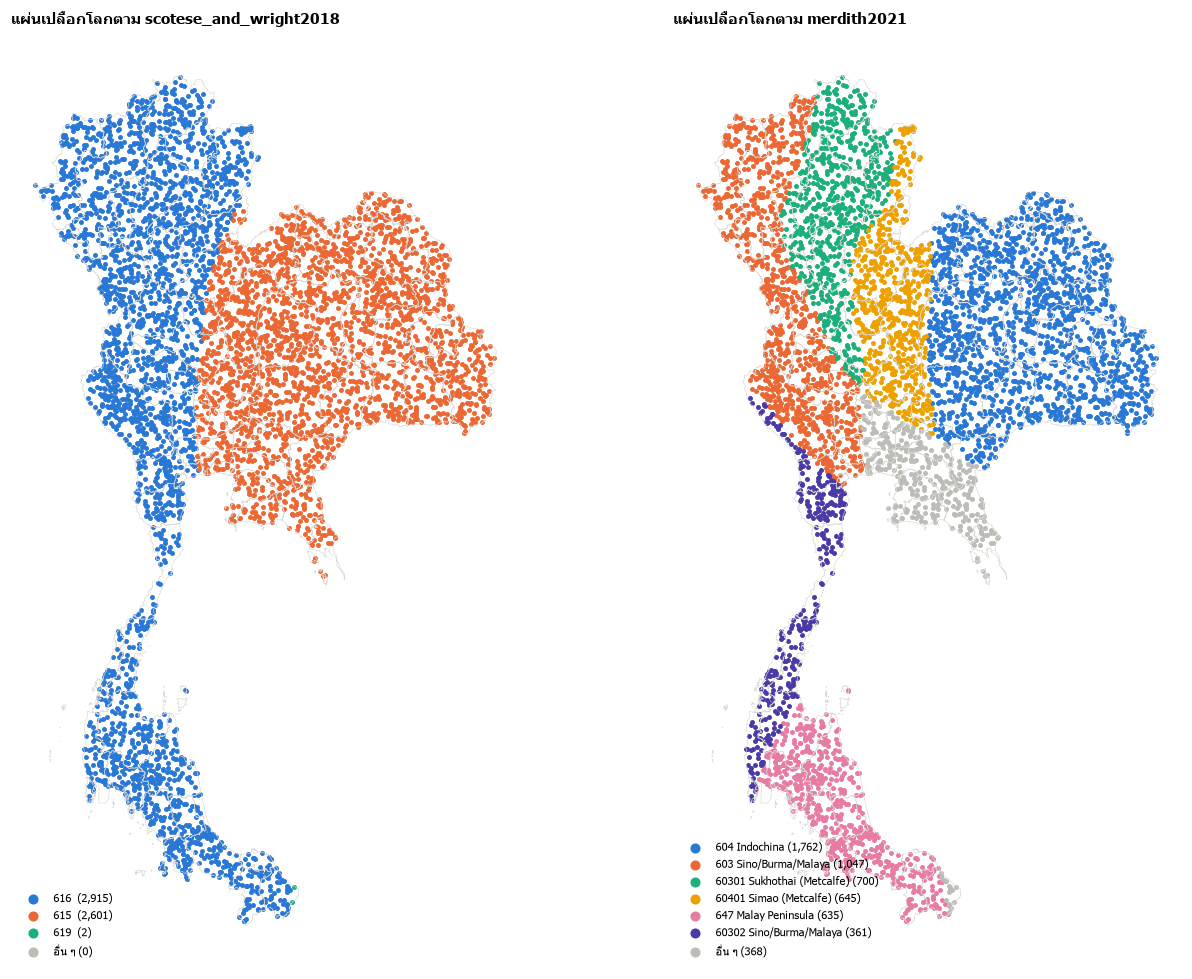

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
for ax, key in zip(axes, MODELS):
    d = parts[key].merge(points, on="point_id")
    d = d[d.source.isin(["bg_uniform", "dmr_site"])]
    top = d[f"pg_{key}_plate"].value_counts().head(6).index
    palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
    prov.boundary.plot(ax=ax, color="#d9d8d3", linewidth=0.4)
    for c, pid in zip(palette, top):
        sub = d[d[f"pg_{key}_plate"].eq(pid)]
        name = (sub[f"pg_{key}_terrane"].dropna().iloc[0] if sub[f"pg_{key}_terrane"].notna().any() else "")[:22]
        ax.scatter(sub.lon, sub.lat, s=5, color=c, label=f"{int(pid)} {name} ({len(sub):,})")
    rest = d[~d[f"pg_{key}_plate"].isin(top)]
    ax.scatter(rest.lon, rest.lat, s=5, color="#bdbcb6", label=f"อื่น ๆ ({len(rest):,})")
    ax.set_axis_off()
    ax.legend(loc="lower left", frameon=False, fontsize=7.5, markerscale=2.5)
    ax.set_title(f"แผ่นเปลือกโลกตาม {MODELS[key]}", loc="left", fontweight="bold", fontsize=10)
plt.tight_layout()

## 3. ย้อนตำแหน่ง (reconstruction)

ใช้ finite rotation ของแต่ละแผ่น ณ แต่ละช่วงเวลา หมุนจุดกลับไปยังตำแหน่งในอดีต (ละติจูด/ลองจิจูดโบราณ)
บันทึกผลของแต่ละ (โมเดล, เวลา) เป็นไฟล์แยก ถ้าหยุดกลางทาง รันใหม่จะทำต่อเฉพาะที่ยังไม่มี

In [6]:
def reconstruct(points, key, t):
    cache = CACHE / f"recon_{key}_{t}.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    d = points[["point_id", "lon", "lat"]].merge(parts[key], on="point_id")
    lat_out = np.full(len(d), np.nan)
    lon_out = np.full(len(d), np.nan)
    for pid, idx in d.groupby(f"pg_{key}_plate").indices.items():
        rot = MODEL[key]["rot"].get_rotation(float(t), int(pid))
        valid = d[f"pg_{key}_begin_ma"].values[idx] >= t   # polygon มีอยู่ ณ เวลา t
        for i, ok in zip(idx, valid):
            if ok:
                la, lo = (rot * pygplates.PointOnSphere(d.lat.values[i], d.lon.values[i])).to_lat_lon()
                lat_out[i], lon_out[i] = la, lo
    df = pd.DataFrame({"point_id": d.point_id, f"pg_{key}_lat_{t}": lat_out, f"pg_{key}_lon_{t}": lon_out})
    df.to_parquet(cache, index=False)
    return df


recon = {}
jobs = [(k, t) for k in MODELS for t in TIMES]
for key, t in tqdm(jobs, desc="reconstruct (โมเดล × เวลา)"):
    recon[(key, t)] = reconstruct(points, key, t)

miss = pd.DataFrame({k: [recon[(k, t)].iloc[:, 1].isna().mean() for t in TIMES] for k in MODELS}, index=TIMES).mul(100).round(1)
miss.index.name = "ล้านปี"
print("% จุดที่ย้อนไม่ได้ (polygon ยังไม่เกิด ณ เวลานั้น)")
miss.T

reconstruct (โมเดล × เวลา):   0%|          | 0/28 [00:00<?, ?it/s]

reconstruct (โมเดล × เวลา): 100%|██████████| 28/28 [00:00<00:00, 483.42it/s]

% จุดที่ย้อนไม่ได้ (polygon ยังไม่เกิด ณ เวลานั้น)


ล้านปี,480,400,300,280,270,260,250,240,230,200,150,120,66,0
sw18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
me21,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. ความสูง/ความลึกโบราณ (PaleoDEM)

ดึงค่าความสูงจาก PaleoDEM ณ ตำแหน่งที่ย้อนด้วย **Scotese & Wright 2018** (ต้องใช้โมเดลเดียวกับที่สร้าง PaleoDEM)
ค่าติดลบ = ใต้ทะเล → `marine` = 1 (ใช้ bilinear interpolation บนกริด 0.2°)

In [7]:
DEM_FILES = {}
for f in glob.glob(str(DATA / "paleo" / "paleodem_0.2deg" / "paleoDEM_0.2Deg_grids" / "*.nc")):
    ma = float(re.search(r"_([\d.]+)Ma\.nc$", f).group(1))
    DEM_FILES[ma] = f


def dem_for(t):
    ma = min(DEM_FILES, key=lambda m: abs(m - t))
    return ma, DEM_FILES[ma]


def paleodem(t):
    cache = CACHE / f"paleodem_{t}.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    ma, f = dem_for(t)
    r = recon[("sw18", t)]
    z = np.full(len(r), np.nan)
    ok = r[f"pg_sw18_lat_{t}"].notna().values
    with xr.open_dataset(f) as ds:
        z[ok] = ds.z.interp(lat=xr.DataArray(r.loc[ok, f"pg_sw18_lat_{t}"].values, dims="p"),
                            lon=xr.DataArray(r.loc[ok, f"pg_sw18_lon_{t}"].values, dims="p")).values
    df = pd.DataFrame({"point_id": r.point_id, f"pg_dem_{t}": z, f"pg_marine_{t}": np.where(np.isnan(z), np.nan, (z < 0).astype(float))})
    df.attrs["dem_ma"] = ma
    df.to_parquet(cache, index=False)
    return df


print("เวลา → ไฟล์ PaleoDEM ที่ใช้:", {t: dem_for(t)[0] for t in TIMES})
dem = {t: paleodem(t) for t in tqdm(TIMES, desc="PaleoDEM")}

เวลา → ไฟล์ PaleoDEM ที่ใช้: {480: 480.0, 400: 400.0, 300: 300.0, 280: 280.0, 270: 270.0, 260: 260.0, 250: 250.0, 240: 240.0, 230: 230.0, 200: 200.0, 150: 150.0, 120: 120.0, 66: 65.0, 0: 0.0}


PaleoDEM:   0%|          | 0/14 [00:00<?, ?it/s]

PaleoDEM: 100%|██████████| 14/14 [00:00<00:00, 635.76it/s]

## 5. รวมเป็นตาราง feature และสร้าง feature สรุป

| feature | ความหมาย |
|---|---|
| `pg_{model}_plate`, `pg_{model}_terrane` | แผ่นเปลือกโลก/terrane ปัจจุบันของจุด |
| `pg_{model}_lat_{t}`, `pg_{model}_lon_{t}` | ละติจูด/ลองจิจูดโบราณ ณ เวลา t |
| `pg_{model}_abslat_{t}` | ระยะจากเส้นศูนย์สูตร (บอกเขตภูมิอากาศโบราณ: < 23.5° เขตร้อน) |
| `pg_dem_{t}`, `pg_marine_{t}` | ความสูงโบราณ และเป็นทะเลไหม ณ เวลา t |
| `pg_n_marine` | จำนวนช่วงเวลาที่เป็นทะเล (จาก 14 ช่วง) |
| `pg_youngest_marine_ma` | ช่วงเวลาล่าสุดที่จุดนี้ยังเป็นทะเล (บอกว่าตะกอนทะเลอายุอ่อนสุดน่าจะเป็นยุคไหน) |
| `pg_{model}_drift_lat_250_0` | ละติจูดที่เปลี่ยนไปตั้งแต่พันเจียถึงปัจจุบัน |

In [8]:
feat = points.copy()
for key in MODELS:
    feat = feat.merge(parts[key], on="point_id", how="left")
    for t in TIMES:
        feat = feat.merge(recon[(key, t)], on="point_id", how="left")
        feat[f"pg_{key}_abslat_{t}"] = feat[f"pg_{key}_lat_{t}"].abs()
    feat[f"pg_{key}_drift_lat_250_0"] = feat[f"pg_{key}_lat_0"] - feat[f"pg_{key}_lat_250"]
for t in TIMES:
    feat = feat.merge(dem[t], on="point_id", how="left")

marine = feat[[f"pg_marine_{t}" for t in TIMES]]
feat["pg_n_marine"] = marine.sum(axis=1, min_count=1)
feat["pg_youngest_marine_ma"] = marine.apply(lambda r: min([t for t, v in zip(TIMES, r.values) if v == 1], default=np.nan), axis=1)

all_nan = [c for c in feat.columns if c.startswith("pg_") and feat[c].isna().all()]
feat = feat.drop(columns=all_nan)
print("ตัดคอลัมน์ที่ว่างทั้งหมด (Merdith ย้อนไทยได้ถึง 410 ล้านปี):", all_nan)
PG_COLS = [c for c in feat.columns if c.startswith("pg_")]
num_cols = [c for c in PG_COLS if not c.endswith("_terrane")]
print(f"feature ทั้งหมด {len(PG_COLS)} คอลัมน์ | จุด {len(feat):,}")
nan_rate = feat[PG_COLS].isna().mean().mul(100)
print("คอลัมน์ที่มีค่าว่าง:", {c: round(v, 1) for c, v in nan_rate[nan_rate > 0].items()})
feat[["point_id", "source"] + PG_COLS[:8]].head()

ตัดคอลัมน์ที่ว่างทั้งหมด (Merdith ย้อนไทยได้ถึง 410 ล้านปี): ['pg_me21_lat_480', 'pg_me21_lon_480', 'pg_me21_abslat_480']
feature ทั้งหมด 119 คอลัมน์ | จุด 10,808
คอลัมน์ที่มีค่าว่าง: {}


,point_id,source,pg_sw18_plate,pg_sw18_terrane,pg_sw18_begin_ma,pg_sw18_lat_480,pg_sw18_lon_480,pg_sw18_abslat_480,pg_sw18_lat_400,pg_sw18_lon_400
0,dmr_11175,dmr_site,615,,4500.0,33.916789,133.789625,33.916789,13.812023,129.487333
1,dmr_11176,dmr_site,616,,4500.0,33.636434,149.476089,33.636434,7.431497,141.052522
2,dmr_11177,dmr_site,616,,4500.0,26.996752,150.490708,26.996752,1.020683,139.109137
3,dmr_11178,dmr_site,616,,4500.0,23.925667,151.976810,23.925667,-2.330603,139.103419
4,dmr_11179,dmr_site,615,,4500.0,33.764332,136.381517,33.764332,12.579285,131.306831


## 6. ตรวจว่า feature มีความหมายไหม

### 6.1 เส้นทางละติจูดของแผ่นเปลือกโลกหลักในไทย

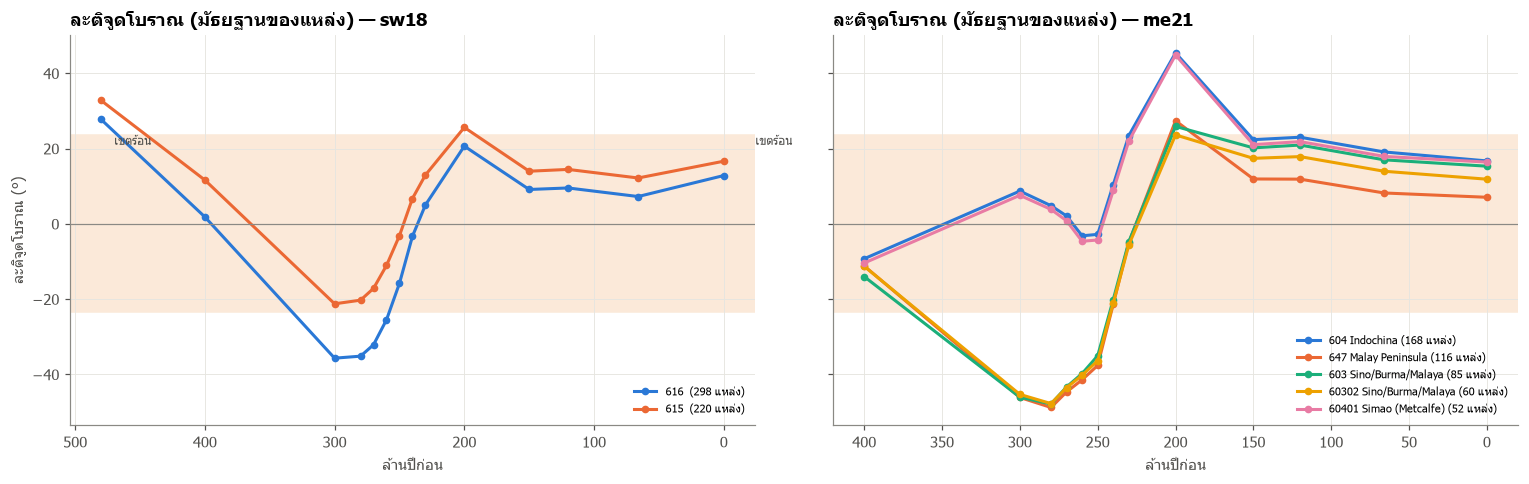

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for ax, key in zip(axes, MODELS):
    d = feat[feat.source.eq("dmr_site")]
    top = d[f"pg_{key}_plate"].value_counts().head(5).index
    for c, pid in zip(palette, top):
        sub = d[d[f"pg_{key}_plate"].eq(pid)]
        ts = [t for t in TIMES if f"pg_{key}_lat_{t}" in sub]
        lat = sub[[f"pg_{key}_lat_{t}" for t in ts]].median()
        name = (sub[f"pg_{key}_terrane"].dropna().iloc[0] if sub[f"pg_{key}_terrane"].notna().any() else "")[:20]
        ax.plot(ts, lat.values, color=c, lw=2, marker="o", ms=4, label=f"{int(pid)} {name} ({len(sub)} แหล่ง)")
    ax.axhspan(-23.5, 23.5, color="#fbe9d9", zorder=0)
    ax.text(470, 21, "เขตร้อน", fontsize=8, color=INK)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.invert_xaxis()
    ax.set_xlabel("ล้านปีก่อน")
    ax.set_title(f"ละติจูดโบราณ (มัธยฐานของแหล่ง) — {key}")
    ax.legend(frameon=False, fontsize=7.5, loc="lower right")
axes[0].set_ylabel("ละติจูดโบราณ (°)")
plt.tight_layout()

### 6.2 ไทยบนแผนที่โลกโบราณ (PaleoDEM, Scotese & Wright 2018)

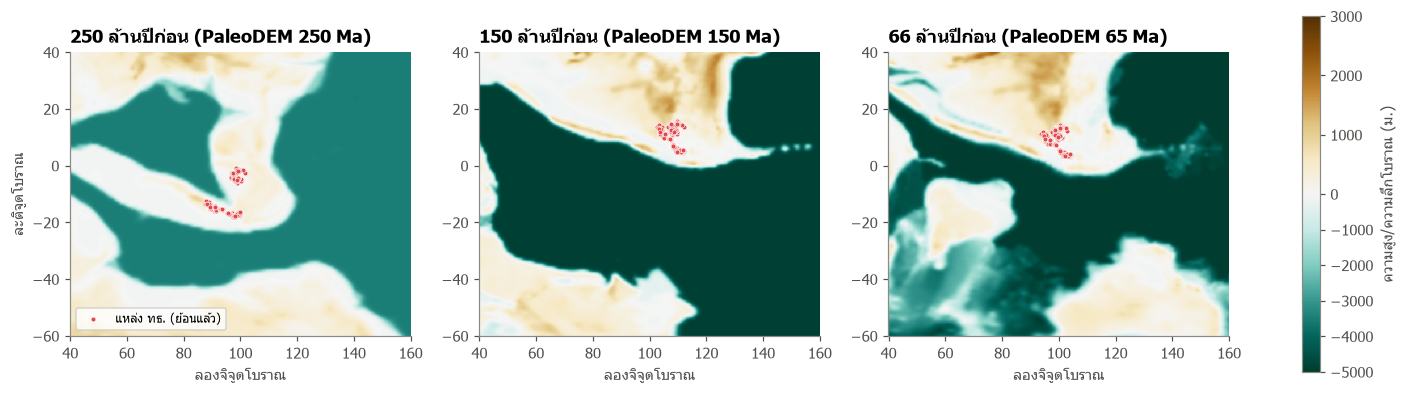

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
d = feat[feat.source.eq("dmr_site")]
for ax, t in zip(axes, [250, 150, 66]):
    ma, f = dem_for(t)
    with xr.open_dataset(f) as ds:
        sub = ds.z.sel(lon=slice(40, 160), lat=slice(-60, 40))
        im = ax.pcolormesh(sub.lon, sub.lat, sub.values, cmap="BrBG_r", norm=TwoSlopeNorm(vmin=-5000, vcenter=0, vmax=3000), shading="auto")
    ax.scatter(d[f"pg_sw18_lon_{t}"], d[f"pg_sw18_lat_{t}"], s=10, color="#e34948", edgecolor="white", linewidth=0.4, label="แหล่ง ทธ. (ย้อนแล้ว)")
    ax.set_title(f"{t} ล้านปีก่อน (PaleoDEM {ma:g} Ma)")
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("ลองจิจูดโบราณ")
axes[0].set_ylabel("ละติจูดโบราณ")
axes[0].legend(frameon=True, fontsize=8, loc="lower left")
fig.colorbar(im, ax=axes, shrink=0.7, label="ความสูง/ความลึกโบราณ (ม.)")

### 6.3 feature โบราณสัมพันธ์กับชนิดซากไหม

ใช้ตัวอย่างที่เชื่อมแหล่งได้ (notebook 02, ความเชื่อมั่น high/medium) ดูว่าแต่ละกลุ่มซากพบในจุดที่เป็นทะเลกี่ช่วงเวลา
และยุคล่าสุดที่จุดนั้นยังเป็นทะเล

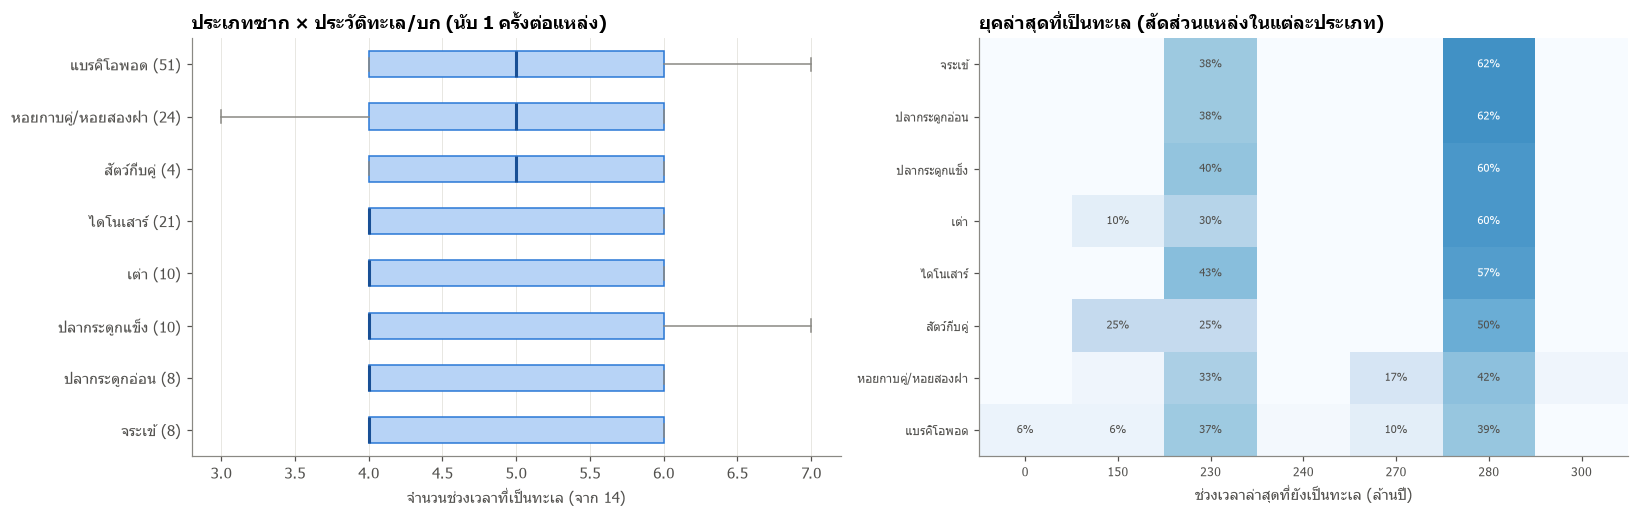

In [11]:
spec = pd.read_csv(DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"},
                   encoding="utf-8-sig", low_memory=False)
spec = spec[spec.confidence.isin(["high", "medium"])]
top_types = spec.f_type.value_counts().head(8).index
j = spec[spec.f_type.isin(top_types)].assign(point_id="dmr_" + spec.site_OBJECTID.astype(str)).merge(feat, on="point_id")
# ถ่วงต่อแหล่ง: นับ (ประเภท, แหล่ง) ไม่ซ้ำ เพื่อไม่ให้แหล่งที่มีตัวอย่างหลายร้อยชิ้นครอบงำ
js = j.drop_duplicates(["f_type", "point_id"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
order = js.groupby("f_type").pg_n_marine.median().sort_values().index
data = [js.loc[js.f_type.eq(t), "pg_n_marine"].dropna() for t in order]
axes[0].boxplot(data, orientation="horizontal", tick_labels=[f"{t} ({len(v)})" for t, v in zip(order, data)], patch_artist=True,
                boxprops=dict(facecolor="#b7d3f6", color="#2a78d6"), medianprops=dict(color="#184f95", lw=2),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED), flierprops=dict(markeredgecolor=MUTED, markersize=3))
axes[0].set_xlabel(f"จำนวนช่วงเวลาที่เป็นทะเล (จาก {len(TIMES)})")
axes[0].set_title("ประเภทซาก × ประวัติทะเล/บก (นับ 1 ครั้งต่อแหล่ง)")
axes[0].grid(axis="y", visible=False)

ct = pd.crosstab(js.f_type, js.pg_youngest_marine_ma.fillna(-1).astype(int)).reindex(order)
ct = ct.rename(columns={-1: "ไม่เคย"}).div(ct.sum(axis=1), axis=0)
im = axes[1].imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(ct.shape[1]), [str(c) for c in ct.columns], fontsize=8)
axes[1].set_yticks(range(ct.shape[0]), ct.index, fontsize=8)
axes[1].set_xlabel("ช่วงเวลาล่าสุดที่ยังเป็นทะเล (ล้านปี)")
axes[1].set_title("ยุคล่าสุดที่เป็นทะเล (สัดส่วนแหล่งในแต่ละประเภท)")
axes[1].grid(False)
for i in range(ct.shape[0]):
    for k in range(ct.shape[1]):
        v = ct.values[i, k]
        if v >= 0.05:
            axes[1].text(k, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else INK)
plt.tight_layout()

**อ่านผล**
- **ทะเล/บกจาก PaleoDEM แยกประเภทซากได้น้อย** (ดูกราฟด้านบนว่าช่วงเพอร์เมียน–ไทรแอสซิกที่เพิ่มเข้ามาช่วยได้แค่ไหน):
  PaleoDEM เป็นแผนที่ระดับโลก (0.2° ≈ 22 กม. และปรับให้เรียบ) ไม่เห็นแอ่งตะกอนระดับท้องถิ่น
  จุดใกล้กันในภูมิภาคเดียวกันจึงได้ประวัติทะเล/บกเหมือนกันเกือบทั้งหมด
- **ส่วนที่มีประโยชน์ชัดเจนคือแผ่นเปลือกโลก/terrane และเส้นทางละติจูด**: Merdith แบ่งไทยเป็น 6 terrane และ Sibumasu กับ Indochina
  อยู่ห่างกันเกือบ 50° ที่ 300 ล้านปี (ส่วน 6.1) ซึ่งตรงกับธรณีวิทยาไทยที่ซากยุคพาลีโอโซอิกฝั่งตะวันตก/ใต้ต่างจากฝั่งอีสาน
- feature โบราณเป็น feature **ระดับภูมิภาค** จุดใกล้กันได้ค่าเกือบเท่ากัน จึงช่วยบอก "ภูมิภาคไหนน่าจะพบอะไร" มากกว่าบอก "จุดไหนในภูมิภาคมีซาก"
  งานแยกจุดในระดับท้องถิ่นต้องพึ่ง feature ดาวเทียม/ภูมิประเทศในขั้นที่ 2

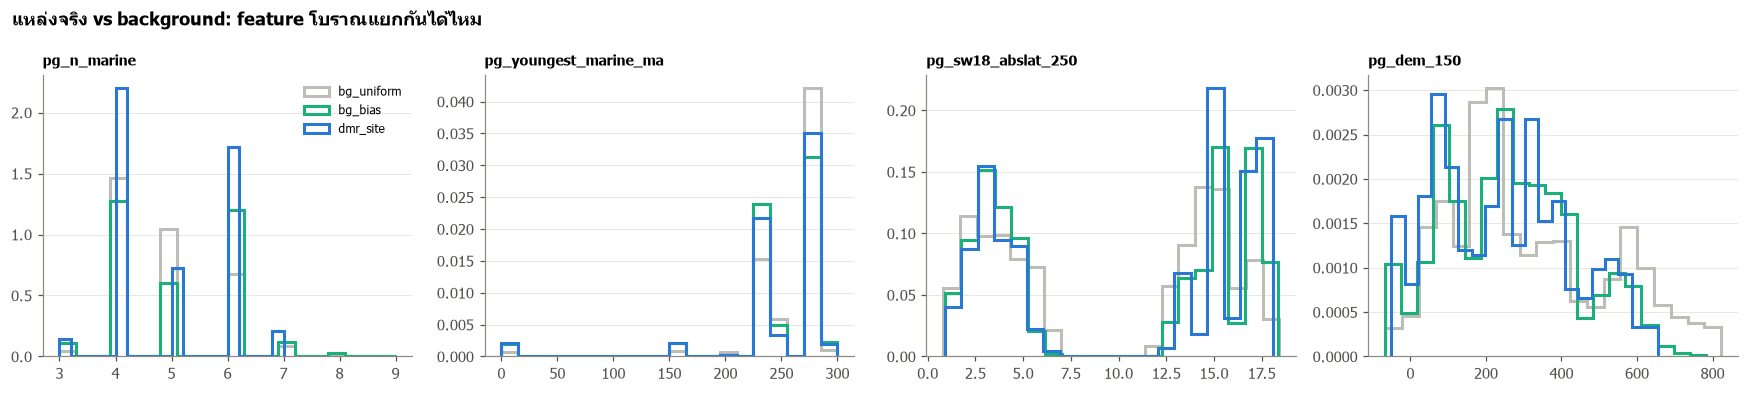

In [12]:
d = feat[feat.source.isin(["dmr_site", "bg_uniform", "bg_bias"])]
cols = ["pg_n_marine", "pg_youngest_marine_ma", "pg_sw18_abslat_250", "pg_dem_150"]
fig, axes = plt.subplots(1, len(cols), figsize=(16, 3.6))
for ax, c in zip(axes, cols):
    for s in ["bg_uniform", "bg_bias", "dmr_site"]:
        v = d.loc[d.source.eq(s), c].dropna()
        ax.hist(v, bins=20, density=True, histtype="step", lw=2, color=SOURCE_COLOR[s], label=s)
    ax.set_title(c, fontsize=9)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("แหล่งจริง vs background: feature โบราณแยกกันได้ไหม", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 7. บันทึก

- `data/features/points.parquet`: ชุดจุดทั้งหมด (id, ที่มา, พิกัด)
- `data/features/pangea_features.parquet`: feature ภูมิศาสตร์โบราณต่อจุด
- `data/features/pangea_feature_list.json`: รายชื่อ feature แยกเป็นตัวเลข / หมวดหมู่ และพารามิเตอร์ที่ใช้

In [13]:
feat.to_parquet(FEAT / "pangea_features.parquet", index=False)
meta = {
    "times_ma": TIMES, "models": MODELS, "paleodem": "Scotese & Wright 2018 PaleoDEM 0.2deg",
    "dem_time_used": {str(t): dem_for(t)[0] for t in TIMES},
    "numeric": [c for c in PG_COLS if not c.endswith("_terrane")],
    "categorical": [c for c in PG_COLS if c.endswith("_terrane") or c.endswith("_plate")],
    "background": {"n": N_BG, "min_dist_km": MIN_DIST_KM, "kde_sigma_km": KDE_SIGMA_KM, "seed": SEED},
}
(FEAT / "pangea_feature_list.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("บันทึก pangea_features.parquet", feat.shape, "และ pangea_feature_list.json")

บันทึก pangea_features.parquet (10808, 124) และ pangea_feature_list.json
